# Part 1: Network Profiling & PANDA Node Masking

In [ ]:
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from Utils.data_utils import load_ml_100k_data, preprocess_users, preprocess_items, load_ml_100k_fold, create_heterodata

DATA_DIR = 'Data/ml-100k/'
users_df, items_df, ratings_df = load_ml_100k_data(DATA_DIR)
proc_users_df = preprocess_users(users_df)
proc_items_df = preprocess_items(items_df)
train_df, test_df = load_ml_100k_fold(DATA_DIR, fold_idx=1)
hetero_train = create_heterodata(proc_users_df, proc_items_df, train_df)

edge_index = hetero_train['user', 'rates', 'movie'].edge_index
num_users = hetero_train['user'].num_nodes
num_movies = hetero_train['movie'].num_nodes
print('Data Loaded! Nodes: ', num_users + num_movies)

Loading MovieLens 100k data...
Loaded 943 users.
Loaded 1682 items (movies).
Loaded 100000 ratings.
Preprocessing user data...
User data preprocessed.
Preprocessing item data...
Item data preprocessed.

Fold 1 loaded -> 80000 train ratings, 20000 test ratings

Creating HeteroData object...
Added 943 user nodes with features.
Added 1682 movie nodes with features.
Added 80000 user-movie rating edges.
HeteroData object created successfully.
Data Loaded! Nodes:  2625


In [ ]:
def get_panda_masks(edge_index, num_users, num_movies, k_percentile=0.1):
    # In PyG HeteroData, edge_index[0] are users, edge_index[1] are movies
    user_degrees = torch.bincount(edge_index[0], minlength=num_users).float()
    item_degrees = torch.bincount(edge_index[1], minlength=num_movies).float()
    
    q = 1.0 - k_percentile
    user_cutoff = torch.quantile(user_degrees, q)
    item_cutoff = torch.quantile(item_degrees, q)
    
    is_high_dim_user = user_degrees >= user_cutoff
    is_high_dim_item = item_degrees >= item_cutoff
    
    return is_high_dim_user, is_high_dim_item, user_degrees, item_degrees, user_cutoff, item_cutoff


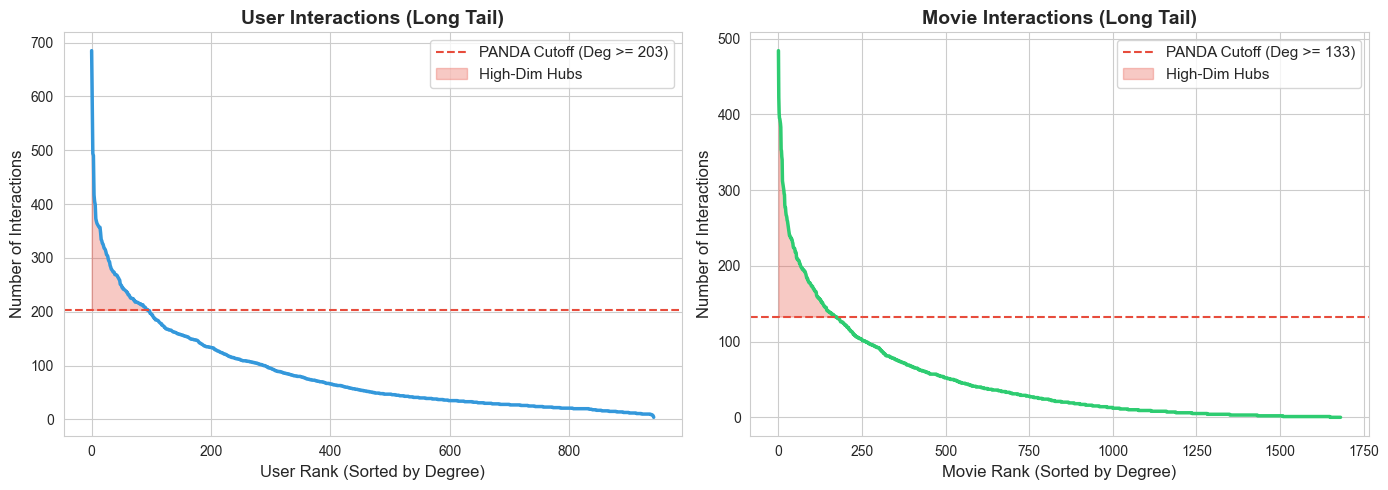

In [ ]:
def plot_panda_profiling(user_degrees, item_degrees, user_cutoff, item_cutoff):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    sns.set_style('whitegrid')
    
    # User Rank-Degree Plot (Long Tail)
    u_deg_sorted, _ = torch.sort(user_degrees, descending=True)
    axes[0].plot(u_deg_sorted.numpy(), color='#3498db', linewidth=2.5)
    axes[0].axhline(user_cutoff.item(), color='#e74c3c', linestyle='--', label=f'PANDA Cutoff (Deg >= {int(user_cutoff)})')
    axes[0].fill_between(range(len(u_deg_sorted)), u_deg_sorted, user_cutoff.item(), where=(u_deg_sorted >= user_cutoff.item()), color='#e74c3c', alpha=0.3, label='High-Dim Hubs')
    axes[0].set_title('User Interactions (Long Tail)', fontsize=14, fontweight='bold')
    axes[0].set_xlabel('User Rank (Sorted by Degree)', fontsize=12)
    axes[0].set_ylabel('Number of Interactions', fontsize=12)
    axes[0].legend(fontsize=11)
    
    # Item Rank-Degree Plot (Long Tail)
    i_deg_sorted, _ = torch.sort(item_degrees, descending=True)
    axes[1].plot(i_deg_sorted.numpy(), color='#2ecc71', linewidth=2.5)
    axes[1].axhline(item_cutoff.item(), color='#e74c3c', linestyle='--', label=f'PANDA Cutoff (Deg >= {int(item_cutoff)})')
    axes[1].fill_between(range(len(i_deg_sorted)), i_deg_sorted, item_cutoff.item(), where=(i_deg_sorted >= item_cutoff.item()), color='#e74c3c', alpha=0.3, label='High-Dim Hubs')
    axes[1].set_title('Movie Interactions (Long Tail)', fontsize=14, fontweight='bold')
    axes[1].set_xlabel('Movie Rank (Sorted by Degree)', fontsize=12)
    axes[1].set_ylabel('Number of Interactions', fontsize=12)
    axes[1].legend(fontsize=11)
    
    plt.tight_layout()
    plt.show()

is_high_dim_u, is_high_dim_i, u_deg, i_deg, u_cut, i_cut = get_panda_masks(edge_index, num_users, num_movies)
plot_panda_profiling(u_deg, i_deg, u_cut, i_cut)


# Part 2: PANDA-LightGCN Message Passing Layer

In [ ]:
from torch import nn, Tensor
from torch_geometric.nn.conv import MessagePassing
from torch_geometric.nn.conv.gcn_conv import gcn_norm

class PANDA_LGConv(MessagePassing):
    def __init__(self, low_dim=64, high_dim=128, normalize=True, **kwargs):
        kwargs.setdefault('aggr', 'add')
        super().__init__(**kwargs)
        self.normalize = normalize
        self.low_dim = low_dim
        self.high_dim = high_dim
        
        self.W_f = nn.Linear(low_dim, high_dim, bias=False)
        self.W_g = nn.Linear(high_dim, low_dim, bias=False)

    def forward(self, x: Tensor, edge_index: Tensor, is_high_dim: Tensor, edge_weight=None) -> Tensor:
        if self.normalize:
            out = gcn_norm(edge_index, edge_weight, x.size(0), add_self_loops=False, dtype=x.dtype)
            edge_index, edge_weight = out
            
        return self.propagate(edge_index, x=x, edge_weight=edge_weight, is_high_dim=is_high_dim)

    def message(self, x_j: Tensor, edge_weight: Tensor, is_high_dim_i: Tensor, is_high_dim_j: Tensor) -> Tensor:
        msg = x_j.clone()
        
        mask_low2high = ((~is_high_dim_j) & is_high_dim_i).squeeze(-1)
        mask_high2low = (is_high_dim_j & (~is_high_dim_i)).squeeze(-1)
        
        if mask_low2high.any():
            low_feats = msg[mask_low2high, :self.low_dim]
            msg[mask_low2high] = self.W_f(low_feats)
            
        if mask_high2low.any():
            high_feats = msg[mask_high2low]
            low_proj = self.W_g(high_feats)
            zeros = torch.zeros(low_proj.size(0), self.high_dim - self.low_dim, device=low_proj.device)
            msg[mask_high2low] = torch.cat([low_proj, zeros], dim=-1)
            
        return msg if edge_weight is None else edge_weight.view(-1, 1) * msg


In [ ]:
# Quick PyG Shape Test
x = torch.randn(4, 128)
is_high_dim = torch.tensor([[True], [False], [True], [False]])
test_edge_index = torch.tensor([[0, 1, 2, 3], [1, 0, 3, 2]])
conv = PANDA_LGConv()
out = conv(x, test_edge_index, is_high_dim)
print('PANDA_LGConv Out shape:', out.shape)


PANDA_LGConv Out shape: torch.Size([4, 128])


# Part 3: Prediction Layer Adaptation

In [ ]:
class PANDAPredictionModule(nn.Module):
    def __init__(self, low_dim=64, high_dim=128):
        super().__init__()
        self.low_dim = low_dim
        self.high_dim = high_dim
        self.W_p = nn.Linear(high_dim, low_dim, bias=False)

    def forward(self, embeddings: Tensor, is_high_dim: Tensor):
        aligned_emb = embeddings[:, :self.low_dim].clone() 
        mask = is_high_dim.squeeze(-1)
        
        if mask.any():
            high_feats = embeddings[mask]
            aligned_emb[mask] = self.W_p(high_feats)
            
        return aligned_emb


In [ ]:
# Dummy integration
prediction_layer = PANDAPredictionModule()
aligned = prediction_layer(out, is_high_dim)
print('Aligned predictions shape (back to 64 dims):', aligned.shape)


Aligned predictions shape (back to 64 dims): torch.Size([4, 64])
